In [3]:
import kagglehub
path = kagglehub.dataset_download("uciml/faulty-steel-plates")

100%|██████████| 102k/102k [00:00<00:00, 529kB/s]


Extracting files...


In [4]:
import os
import pandas as pd
import numpy as np

# List files in the downloaded dataset path
files = os.listdir(path)
print('Files in dataset directory:', files)

# Let's locate the data file (likely a CSV or a txt file)
data_file = None
for file in files:
    if file.endswith('.csv') or 'Faults' in file or 'data' in file:
        data_file = os.path.join(path, file)
        break

print('Selected data file:', data_file)

Files in dataset directory: ['faults.csv']
Selected data file: /root/.cache/kagglehub/datasets/uciml/faulty-steel-plates/versions/1/faults.csv


In [9]:
# Load dataset correctly using comma separation and parsing header naturally
df = pd.read_csv(data_file)
print(f'Successfully loaded with shape: {df.shape}')
display(df.head())

Successfully loaded with shape: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


Distribution of Faults:
Pastry          158
Z_Scratch       190
K_Scatch        391
Stains           72
Dirtiness        55
Bumps           402
Other_Faults    673
dtype: int64


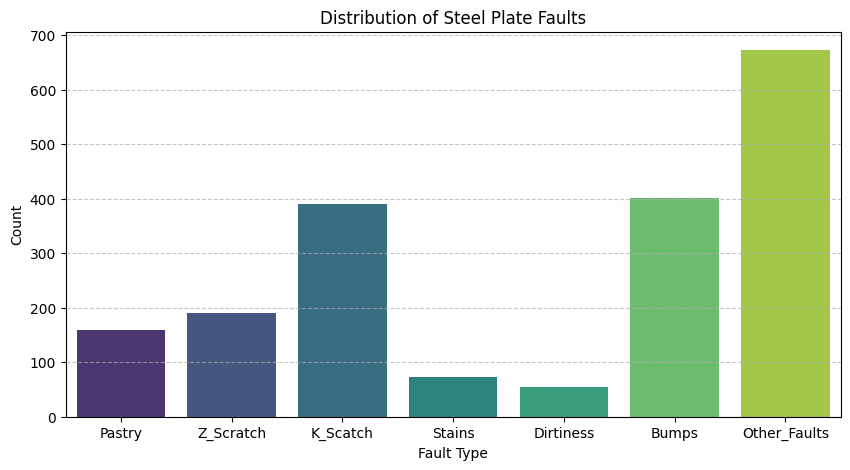

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correct target columns representing 1-hot encoded fault types (noting 'K_Scatch' spelling)
target_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# Summary of fault distributions
fault_sums = df[target_cols].sum()
print("Distribution of Faults:")
print(fault_sums)

plt.figure(figsize=(10, 5))
# Assign x to hue and set legend=False to resolve the seaborn warning
sns.barplot(x=fault_sums.index, y=fault_sums.values, hue=fault_sums.index, palette='viridis', legend=False)
plt.title('Distribution of Steel Plate Faults')
plt.ylabel('Count')
plt.xlabel('Fault Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Features are all columns except the 7 target classes
X = df.drop(columns=target_cols)

# Convert 1-hot encoded targets to a single categorical target series for multi-class classification
y = df[target_cols].idxmax(axis=1)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Evaluate the model
y_pred = clf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8021

Classification Report:
              precision    recall  f1-score   support

       Bumps       0.75      0.72      0.73        81
   Dirtiness       0.89      0.73      0.80        11
    K_Scatch       0.97      0.91      0.94        78
Other_Faults       0.72      0.85      0.78       135
      Pastry       0.64      0.50      0.56        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.84      0.90        38

    accuracy                           0.80       389
   macro avg       0.84      0.77      0.80       389
weighted avg       0.81      0.80      0.80       389



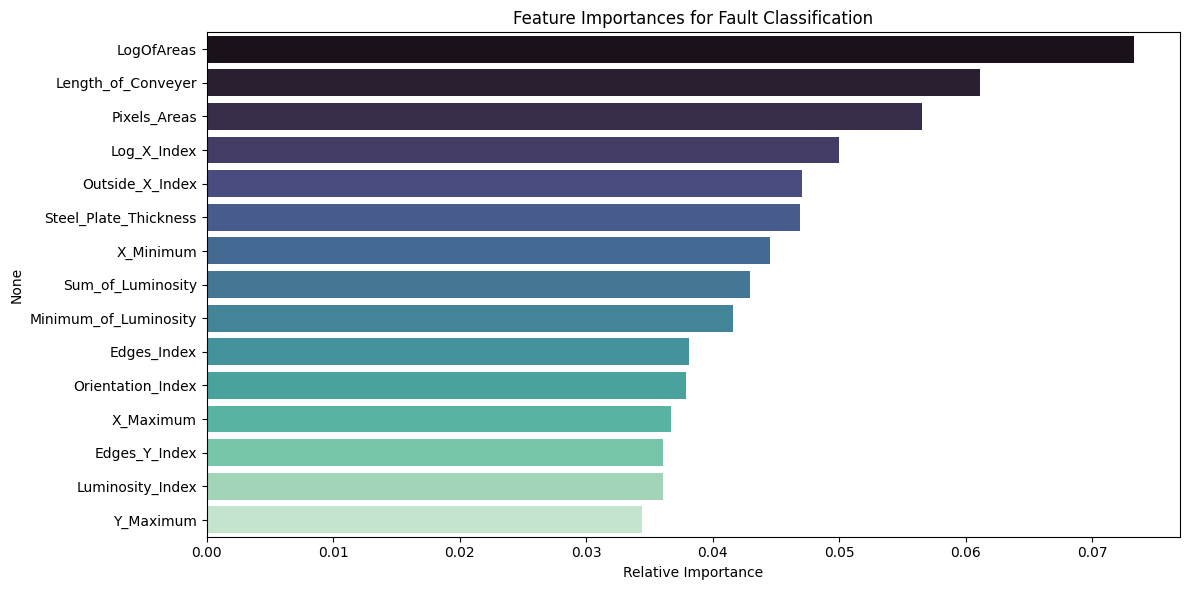

In [18]:
# Access or retrain the classifier if it's missing, then plot feature importances
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    importances = clf.feature_importances_
except NameError:
    # If the cell is run independently, recreate the classifier from the active state
    from sklearn.ensemble import RandomForestClassifier
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train, y_train)
    importances = clf.feature_importances_

indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Feature Importances for Fault Classification")
# Assign y to hue to resolve the seaborn palette warning
sns.barplot(x=importances[indices][:15], y=X.columns[indices][:15], hue=X.columns[indices][:15], palette='mako', legend=False)
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

In [19]:
# Save the trained model first using pickle so the Streamlit app can load it easily
import pickle

model_artifacts = {
    'model': clf,
    'feature_names': list(X.columns),
    'target_cols': target_cols
}

with open('model_artifacts.pkl', 'wb') as f:
    pickle.dump(model_artifacts, f)

print("Model artifacts saved successfully!")

Model artifacts saved successfully!


In [20]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle

st.set_page_config(page_title="Steel Plate Fault Classifier", layout="wide")

# Load the trained model artifacts
@st.cache_resource
def load_model():
    with open('model_artifacts.pkl', 'rb') as f:
        return pickle.load(f)

artifacts = load_model()
model = artifacts['model']
feature_names = artifacts['feature_names']
target_cols = artifacts['target_cols']

st.title("⚙️ Steel Plate Fault Classifier")
st.write("This application uses a Random Forest Classifier to predict the type of steel plate defect based on geometric and physical properties.")

# Input panel in the left sidebar
st.sidebar.header("🔧 Input Plate Features")

# We'll group features in the sidebar for better readability
input_data = {}
for col in feature_names:
    # Define sensible defaults/ranges based on column type or key characteristics
    if 'TypeOfSteel' in col or 'Index' in col or 'Ratio' in col or 'Sigmoid' in col or 'Orientation' in col:
        min_val, max_val, default_val = 0.0, 1.0, 0.5
        if 'TypeOfSteel' in col:
            default_val = 0.0
        input_data[col] = st.sidebar.slider(f"{col}", float(min_val), float(max_val), float(default_val))
    else:
        # Integer values or larger range values
        input_data[col] = st.sidebar.number_input(f"{col}", value=0.0)

# Predict button and results on the main screen
input_df = pd.DataFrame([input_data])

st.subheader("📊 Entered Input Parameters")
st.dataframe(input_df)

if st.button("Predict Fault Type"):
    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    st.success(f"### Predicted Fault: **{prediction}**")

    # Display prediction confidence details
    prob_df = pd.DataFrame({
        'Fault Type': model.classes_,
        'Probability': probabilities
    }).sort_values(by='Probability', ascending=False)

    st.subheader("📈 Prediction Confidence Breakdown")
    st.bar_chart(data=prob_df, x='Fault Type', y='Probability')


Writing app.py


In [22]:
!pip install --ignore-installed blinker
!pip install streamlit

In [23]:
!pip install streamlit pyngrok

In [24]:
from pyngrok import ngrok
ngrok.set_auth_token("3H2nxZtP4iC5L9tX9K97OPLut9W_4JsZrRVF5aRFQpQCCePy1")

In [25]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print(public_url)

NgrokTunnel: "https://vanity-amperage-commodore.ngrok-free.dev" -> "http://localhost:8501"


In [26]:
# Run the Streamlit app
# This will provide a public URL to access the app
!streamlit run app.py &




2026-10-24 13:35:07.719 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.34.51.234:8501

  Stopping...
